## Table of Contents

#### Part I: Research Question

A1. [Research Question](#A1.-Research-Question)

A2. [Goals](#A2.-Goals)

#### Part II: Method Justification

B1. [Explanation of Prediction](#B1.-Explanation-of-Prediction)

B2. [Summary of Method Assumptions](#B2.-Summary-of-Method-Assumptions)

B3. [Packages and Libraries](#B3.-Packages-and-Libraries)

#### Part III: Data Preparation

C1. [Data Preprocessing](#C1.-Data-Preprocessing)

C2. [Dataset Variables](#C2.-Dataset-Variables)

C3. [Steps for Analysis](#C3.-Steps-for-Analysis)

C4. [Cleaned Dataset](#C4.-Cleaned-Dataset)

#### Part IV: Analysis

D1. [Splitting the Data](#D1.-Splitting-the-Data)

D2. [Output and Intermediate Calculations](#D2.-Output-and-Intermediate-Calculations)

D3. [Code Execution](#D3.-Code-Execution)

#### Part V: Data Summary and Implications

E1. [Accuray and MSE](#E1.-Accuracy-and-MSE)

E2. [Results and Implications](#E2.-Results-and-Implications)

E3. [Limitations](#E3.-Limitations)

E4. [Course of Action](#E4.-Course-of-Action)

#### Part VI: Demonstration


G. [Sources of Third-Party Code](#G.-Sources-of-Third-Party-Code)

H. [Sources](#H.-Sources)

### Part I: Research Question

#### A1. Research Question

The research question for this performance assessment will be, "Can a random forest classifier be built that accurately predicts customer churn?" To answer this question, I will be using the Churn dataset to build a random forest classifier. This dataset contains records from a fictional ISP, including data pertaining to each customer's churn status.

#### A2. Goals

The goal of this performance assessment will be to create a Random Forest Classifier that can accurately classify a participant's churned status. For the purposes of this assignment, "accuracy" will be in measured both in terms of classification accuracy and ROC AUC. Relative performance of the model will be assessed through comparison of the RF Classifier against the K-Nearest-Neighbors Classifier I built in Task 1; the KNN model had an accuracy score of 0.82 and an AUC of 0.875, with an F1-score for negative test cases of 0.88 and an F1-score for positive cases of 0.63.

### Part II: Method Justification

#### B1. Explanation of Prediction

The prediction method selected for this assessment is a Random Forest Classifier. A random forest is an ensemble method consisting of multiple Decision Tree Classifiers; to accurately explain a Random Forest, it's necessary to first explain a Decision Tree.

A Decision Tree Classifier is a supervised machine learning method wherein the input dataset is split into incrementally smaller subsets; the data is split at "Decision Nodes", in which a condition is applied and the data is split based upon the results. For example, an input dataset containing sumo wrestler data might apply a condition based on the wrestler's weight - say, weight >= 200 kg. The decision node would then output two subsets, with one containing all wrestlers who met the critera, and the other containing all wrestlers who do not. These subsets may each be fed into further decision nodes that would apply other conditions based on other factors, such as height or win rate. The ultimate goal of the Decision Tree is to organize the dataset into "Leaf Nodes" - these are points at which no further conditions are applied. These leaf nodes contain predictions based on the data that has reached them. In this sense, a Decision Tree model can be said to visually replicate a tree, with each split point representing branches, and each prediction representing leaves. (Google Developers, 2024)

A Random Forest model is comprised of multiple decision trees; each tree is trained differently, and the resulting predictions are aggregated to form the final predictive model. In the case of Random Forest Classifiers, the final prediction is determined by majority vote between the decision trees. (GeeksForGeeks, 2025)

#### B2. Summary of Method Assumptions

One assumption of the Random Forest model is that aggregating the various predictions of individual decision trees results in an improved level of predictive accuracy. (GeeksForGeeks, 2025) Indeed, the entire concept of the Random Forest model is built upon this assumption; the model itself aggregates the predictions of various individual decision trees in order to generate predictions.

#### B3. Packages and Libraries

I'll be using Python to perform this analysis. Python is a free and open-source programming language that has a number of analytic and machine learning libraries that are purpose-built for this type of task. I'll also be using a number of these libraries, include Pandas, NumPy, Scikit-Learn, and Matplotlib.

Pandas allows for the importation and manipulation of tabular data within special objects called dataframes; these dataframes organize data into columns and rows similar to a spreadsheet, or a table in a relational database. (Pandas Documentation, 2024) Most of the storage and manipulation of data in this project will be done within Pandas dataframes.

NumPy is a package that provides scientific computing capabilities, and also provides support for arrays in the form of the ndarray object. (NumPy Documentation, 2024) This project will make occassional use of NumPy arrays; some other NumPy functions will be used for basic calculations.

Matplotlib is a data visualization package for Python. (Matplotlib Documentation, 2024) This paper will make use of the Matplotlib package to visualize the model's Area-Under-the-Curve (AUC).

Scikit-Learn is a powerful machine learning package that contains functionality essential for building out many ML models, including decision trees and random forests. It also has preprocessing functionalities that will be used to prepare the data for use in these models. (Scikit-Learn Documentation, 2024)

### Part III: Data Preparation

#### C1. Data Preprocessing

One of the data preprocessing goals for this analysis will be to identify and remove duplicate records within the input dataset. This will be done both for observations that match across all columns, as well as for observations that match within individual columns that are intended to contain unique values (in this case, Customer_Id and Interaction). Duplicate records, or duplicate data within columns intended to hold unique data, can indicate "bad" data - that could be data that was incorrectly collected, data that was erroneously entered twice, or data that become malformed or inaccurate for some other reason. Excluding this data before training the model is of paramount importance, as this will prevent the model from being built on inaccurate or erroneous data.

#### C2. Dataset Variables

The initial variables used as part of this analysis are as follows:

1. Area - Describes the region the customer resides in; categorical.
2. Children - Number of children in the customer's household; numeric.
3. Age - Customer's age; numeric.
4. Income - Customer's income; numeric.
5. Marital - Customer's marital status; categorical.
6. Gender - Customer's gender; categorical.
7. Churn - Customer's churn status; categorical.
8. Outage_sec_perweek - Measure of service outage time, measured in average seconds per week; numeric.
9. Email - Count of emails sent to customer within the past year; numeric.
10. Contacts - Total count of times customer has contacted customer support; numeric.
11. Yearly_equip_failure - Number of customer equipment failure incidents within the past year; numeric.
12. Techie - Whether the customer identifies as being technically inclined; categorical.
13. Contract - Customer’s contract term; categorical.
14. Port_modem - Whether the customer has a portable modem; categorical.
15. Tablet - Whether the customer has a tablet; categorical.
16. InternetService - Type of internet service provided to the customer; categorical.
17. Phone - Whether or not the customer has a phone service; categorical.
18. Multiple - Whether the customer subscribes to multiple phone lines; categorical.
19. OnlineSecurity - Whether the customer has the online security add-on service; categorical.
20. OnlineBackup - Whether the customer has the online back-up add-on service; categorical.
21. DeviceProtection - Whether the customer has the device protection add-on service; categorical.
22. TechSupport - Whether the customer has the technical support add-on service; categorical.
23. StreamingTV - Whether or not the customer has a television streaming service; categorical.
24. StreamingMovies - Whether or not the customer has a movie streaming service; categorical.
25. PaperlessBilling - Whether the customer has paperless billing; categorical.
26. PaymentMethod - The customer’s method of payment; categorical.
27. Tenure - The number of months that the customer has been actively subscribed with the service provider; numeric.
28. MonthlyCharge - Average amount charged to customer on a monthly basis; numeric.
29. Bandwidth_GB_Year - Average amount of data used by the customer over the past year, measured in GB; numeric.

#### C3. Steps for Analysis

The code used below to clean the input Churn dataset is partially re-used from my earlier projects in this degree program, including for Task 1 of D209. As the same Churn dataset was used in that assessment, the code is capable of performing similar data cleaning tasks for this use case. 

This code performs the following functions:

1. Imports the packages necessary to complete the data cleaning task: pandas and numpy.
2. Finds complete duplicate records within the data (that is, records that are complete duplicates of one another across all columns). If complete duplicates are found, the code returns "True"; otherwise it returns a "False."
3. Finds duplicate values that are expected to be unique, based on the definitions provided in the data dictionary for the Churn dataset. These columns are 'Customer_id' and 'Interaction'. The code returns a True or False for each of these columns, depending on whether or not dupes are found.
4. Searchings for missing/null columns across all records, and then returns a list of columns that have missing values. If no missing data is found, it will return the message "No missing data found."
5. Evaluates all columnss that should be confined to values of "Yes" or "No", and prints a list of columns that contain values other than these two. The columns being evaluated are 'Churn', 'Techie', 'Port_modem', 'Tablet', 'Phone', 'Multiple', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', and 'PaperlessBilling'. If no invalid values are found, the code prints the message "No invalid boolean values found."
6. Evaluates all categorical columns to ensure that they only contain valid values as defined in the data dictionary. The columns evaluated are 'Gender', 'Marital', 'Area', 'Contract', 'InternetService', and 'PaymentMethod'. The code will print out a list of columns that have invalid values; if none are found, it will return "No invalid categorical values found".
7. Removes the columns that are unnecessary for this analysis - Customer_id, Interaction, UID, City, State, County, Zip, Lat, Lng, TimeZone, Job, and Items 1 through 8.

In [1]:
# Initial cleaning of dataset

# Import necessary packages
import pandas as pd
import numpy as np

# Import the dataset
churnfile = pd.read_csv('../data/churn_clean.csv',index_col=0, keep_default_na=False, na_values=['NA'])  # 'None' is a valid InternetService value

# Data quality check: Find complete dupes
churnfile_compldupes = churnfile.duplicated()
print("Complete dupes: " + str(churnfile_compldupes.any()))

# Data quality check: Look for dupes on columns that should be unique
uniquecols = ['Customer_id','Interaction']
for cols in (uniquecols):
    churnfile_uniqdupes = churnfile.duplicated(subset=cols, keep=False)
    print("Dupes in column " + cols + ": " + str(churnfile_uniqdupes.any()))

# Data quality check: Look for missing data
missingcols = []
for cols in churnfile:
    if ((churnfile[cols].isnull().sum()) > 0):
        missingcols.append(cols)
if len(missingcols) > 0:
    print("Columns that are missing data: ")
    print(missingcols)
else:
    print("No missing data found")

# Data quality check: Find non-boolean values in boolean vars
boolvars = ['Churn','Techie','Port_modem','Tablet','Phone','Multiple',
            'OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport',
            'StreamingTV','StreamingMovies','PaperlessBilling']
badbools = []
for col in boolvars:
    if churnfile[col][~churnfile[col].isin(["Yes","No"])].any() == True:
        badbools.append(col)
if len(badbools) > 0:
    print("Boolean columns that have out-of-range values: ")
    print(badbools)
else:
    print("No invalid boolean values found")        
    
# Data quality check: Find invalid categorical values
rangecols = {"Gender":['Male','Female','Nonbinary'],
             "Marital":['Married','Separated','Divorced','Never Married','Widowed'],
             "Area":["Rural","Urban","Suburban"],
             "Contract":["One year","Two Year","Month-to-month"],
             "InternetService":["Fiber Optic","DSL","None"],
             "PaymentMethod":["Bank Transfer(automatic)","Credit Card (automatic)",
                              "Electronic Check","Mailed Check"]
            }
badrange = []
for col, val in rangecols.items():
    if churnfile[col][~churnfile[col].isin(val)].any() == True:
        badrange.append(col)
if len(badrange) > 0:
    print("Categorical columns that have invalid values: ")
    print(badrange)
else:
    print("No invalid categorical values found")
    
# Drop extraneous variables from the file
churnfile.drop(["Customer_id","Interaction","UID","City","State","County","Zip","Lat","Lng","TimeZone",
                                 "Job","Item1","Item2","Item3","Item4","Item5","Item6","Item7","Item8"], axis=1, inplace=True)


Complete dupes: False
Dupes in column Customer_id: False
Dupes in column Interaction: False
No missing data found
No invalid boolean values found
No invalid categorical values found


The dataset has now been successfully cleaned; there are no duplicate records, no duplicate values across unique columns, no missing or null values, no invalid boolean or categorical values, and outliers have been successfully removed. The data must now be prepped for building the decision tree model that will serve as the basis for the random forest classifier.

The code below converts all Yes/No values to 0's for No and 1 for Yes; additionally, it also utilizes one-hot encoding to c onvert all categorical variables into numeric columns. Both of these steps are necessary to convert the data into a format that is usable by the decision tree classifier.

In [2]:
# Prepare data for analysis

# Convert Yes/No String Values to Numeric 1/0
for var in boolvars:
    # churnfile[var].replace({"No": 0, "Yes": 1}, inplace=True)
    churnfile.replace({var: {"No": 0, "Yes": 1}}, inplace=True)

# Use One-Hot Encoding to Convert Categorical Variables to Numeric
churn_ohe = pd.get_dummies(churnfile, prefix="Area", columns=["Area"], drop_first=False, dtype=int)
churn_ohe = pd.get_dummies(churn_ohe, prefix="Contract", columns=["Contract"], drop_first=False, dtype=int)
churn_ohe = pd.get_dummies(churn_ohe, prefix="Gender", columns=["Gender"], drop_first=False, dtype=int)
churn_ohe = pd.get_dummies(churn_ohe, prefix="Marital", columns=["Marital"], drop_first=False, dtype=int) 
churn_ohe = pd.get_dummies(churn_ohe, prefix="PaymentMethod", columns=["PaymentMethod"], drop_first=False, dtype=int)
churn_ohe = pd.get_dummies(churn_ohe, prefix="InternetService", columns=["InternetService"], drop_first=False, dtype=int) 

print(churn_ohe.info())
churnfile_cleaned = churn_ohe

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 1 to 10000
Data columns (total 45 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Population                              10000 non-null  int64  
 1   Children                                10000 non-null  int64  
 2   Age                                     10000 non-null  int64  
 3   Income                                  10000 non-null  float64
 4   Churn                                   10000 non-null  int64  
 5   Outage_sec_perweek                      10000 non-null  float64
 6   Email                                   10000 non-null  int64  
 7   Contacts                                10000 non-null  int64  
 8   Yearly_equip_failure                    10000 non-null  int64  
 9   Techie                                  10000 non-null  int64  
 10  Port_modem                              10000 non-null  int64  

In [3]:
print(churnfile_cleaned.head())

           Population  Children  Age    Income  Churn  Outage_sec_perweek  \
CaseOrder                                                                   
1                  38         0   68  28561.99      0            7.978323   
2               10446         1   27  21704.77      1           11.699080   
3                3735         4   50   9609.57      0           10.752800   
4               13863         1   48  18925.23      0           14.913540   
5               11352         0   83  40074.19      1            8.147417   

           Email  Contacts  Yearly_equip_failure  Techie  ...  \
CaseOrder                                                 ...   
1             10         0                     1       0  ...   
2             12         0                     1       1  ...   
3              9         0                     1       1  ...   
4             15         2                     0       1  ...   
5             16         2                     1       0  ...   

    

#### C4. Cleaned Dataset

In [4]:
churnfile_cleaned.to_csv('churnfile_prepared.csv', index=False)

A copy of the cleaned, prepared dataset has been attached as the comma-delimited file, "churnfile_prepared.csv".

### Part IV: Model Comparison and Analysis

#### D1. Splitting the Data

The code below splits the input data into training and test datasets. The training datasets are used to build the initial Random Forest Classifier. After the model has been built, it will be tested using the test datasets created below. For this model, 70% of the data will be used for training, and 30% will be used to measure the model's performance later on.

In [5]:
#Import train_test_split to split the dataset
from sklearn.model_selection import train_test_split

#Assign features and response variables
X = churnfile_cleaned.drop(["Churn"],axis=1)
y = churnfile_cleaned["Churn"].values

#Split 30% of the data for use as a test dataset
#stratify=y ensures that proportionality is kept across test and training data
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=31337,stratify=y)

In [6]:
#Provide a copy of the training dataset
churnfile_cleaned_train = pd.DataFrame(X_train)
churnfile_cleaned_train['Churn'] = y_train.tolist()
print(churnfile_cleaned_train.info())

#Provide a copy of the test dataset
churnfile_cleaned_test = pd.DataFrame(X_test)
churnfile_cleaned_test['Churn'] = y_test.tolist()
print(churnfile_cleaned_test.info())

churnfile_cleaned_train.to_csv('churnfile_cleaned_training.csv',index=False)
churnfile_cleaned_test.to_csv('churnfile_cleaned_testing.csv',index=False)

<class 'pandas.core.frame.DataFrame'>
Index: 7000 entries, 7635 to 2680
Data columns (total 45 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Population                              7000 non-null   int64  
 1   Children                                7000 non-null   int64  
 2   Age                                     7000 non-null   int64  
 3   Income                                  7000 non-null   float64
 4   Outage_sec_perweek                      7000 non-null   float64
 5   Email                                   7000 non-null   int64  
 6   Contacts                                7000 non-null   int64  
 7   Yearly_equip_failure                    7000 non-null   int64  
 8   Techie                                  7000 non-null   int64  
 9   Port_modem                              7000 non-null   int64  
 10  Tablet                                  7000 non-null   int64 

#### D2. Output and Intermediate Calculations

The initial random forest classifier will now be built using the training dataset that were created above. This is done using the RandomForestClassifier function that is imported from scikit-learn. The classifier has a number of hyperparameters that will be set to placeholder values to build the initial model; that model will then be tested against the test datasets.

In [7]:
#Import Classifiers from sklearn, along with metrics and GridSearchCV for RF optimization
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

#Define a seed value to ensure reproducibility of test results
SEED=31337

#Use training data to build initial model
#Hyperparameters are placeholders; these will be updated later after GridSearchCV is used to find optimal values
rf = RandomForestClassifier(n_estimators=650, min_samples_leaf=0.1, max_depth=3, random_state=SEED)
rf.fit(X_train, y_train)

#Predict
y_predictions = rf.predict_proba(X_test)[:,1]

#Get ROC_AUC
rf_RAS = roc_auc_score(y_test, y_predictions)

print('ROC AUC score for initial Random Forest Classifier: {:.3f}'.format(rf_RAS))

ROC AUC score for initial Random Forest Classifier: 0.932


Now that the initial model has been built, I'll determine the best hyperparameters to use to build out an optimal classifier. For this, I'll use GridSearchCV, also from scikit-learn. GridSearchCV can be fed a list of values for the hyperparameters used by the classifier; it will then spin through the classifier, rebuilding the model with every combination of the provided hyperparameters, until it finds the one that has the highest score (in this case, AUC).

In [8]:
#Import GridSearchCV
from sklearn.model_selection import GridSearchCV

#Use GridSearchCV to identify the best hyperparameters for the Random Forest Classifier
#Set parameters for grid
gscv_rf_params = {'n_estimators':[200,350,500,650],
                'min_samples_leaf':[0.1,0.15,0.2,0.25],
                'max_depth':[3,5,7,9],
                 'random_state':[SEED]}

#Instantiate grid serach
rf_grid = GridSearchCV(estimator=rf, param_grid=gscv_rf_params, cv=5, scoring='roc_auc', n_jobs=-1)

#Fit to training data
rf_grid.fit(X_train,y_train)

#Get the  best hyperparameters and best model from GridSearchCV
best_hp = rf_grid.best_params_
rf_final_model = rf_grid.best_estimator_

print(best_hp)

GSCV_y_predictions = rf_grid.predict_proba(X_test)[:,1]

GSCV_RAS = roc_auc_score(y_test, GSCV_y_predictions)

print('ROC AUC score for optimal Random Forest Classifier: {:.3f}'.format(GSCV_RAS))

{'max_depth': 3, 'min_samples_leaf': 0.1, 'n_estimators': 350, 'random_state': 31337}
ROC AUC score for optimal Random Forest Classifier: 0.933


As shown above, the optimal hyperparameters for this model have max_depth = 3, min_samples_leaf = 0.1, and n_estimators = 350. The AUC score for this optimized Random Forest Classifier is 0.933 - this is high and shows that the model is mostly successful when classifying observations relative to each other. However, there is still the possibility of further refinement.

Below I use AdaBoostClassifier from scikit-learn to improve the model further. AdaBoost is short for "adaptive boosting"; this is an ensemble classification method wherein a number of models are trained sequentially, with each model attempting to correct prediction errors based off of the results in the previous model. The end result is a model that should be stronger and more accurate than previously.

In [9]:
#Import AdaBoostClassifier
from sklearn.ensemble import AdaBoostClassifier


adb_clf = AdaBoostClassifier(estimator=rf_final_model, n_estimators=100, random_state = SEED)

adb_clf.fit(X_train, y_train)

# Predict test set probabilities of positive class
y_pred_proba = adb_clf.predict_proba(X_test)[:,1]


# Evaluate teste-set roc_auc_score
adb_clf_roc_auc_score = roc_auc_score(y_test, y_pred_proba)

print('ROC AUC score: {:.3f}'.format(adb_clf_roc_auc_score))

ROC AUC score: 0.957


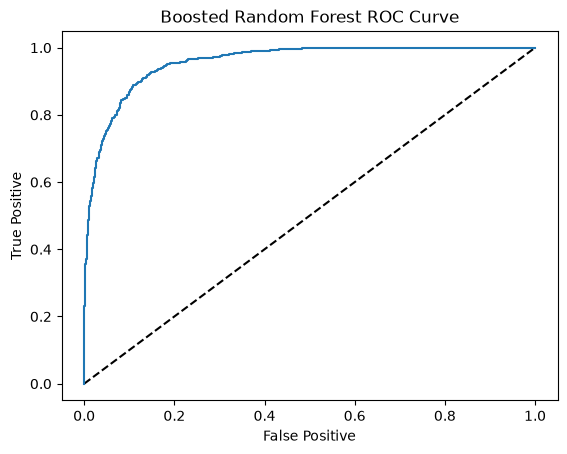

In [10]:
# Calculate and graph the Receiver Operating Characteristic (ROC) curve

from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.plot([0,1], [0,1], 'k--')
plt.plot(fpr, tpr)
plt.xlabel('False Positive')
plt.ylabel('True Positive')
plt.title('Boosted Random Forest ROC Curve')
plt.show()

In [11]:
# Classification report to clarify prediction accuracy
from sklearn.metrics import confusion_matrix, classification_report

preds = adb_clf.predict(X_test)

print(confusion_matrix(y_test, preds))
print(classification_report(y_test, preds))

[[2052  153]
 [ 159  636]]
              precision    recall  f1-score   support

           0       0.93      0.93      0.93      2205
           1       0.81      0.80      0.80       795

    accuracy                           0.90      3000
   macro avg       0.87      0.87      0.87      3000
weighted avg       0.90      0.90      0.90      3000



In [12]:
# Calculate the Mean Squared Error
from sklearn.metrics import mean_squared_error as MSE
mse_test = MSE(y_test, preds)
rmse_test = mse_test**(1/2)
print("Mean Squared Error: {:.3f}".format(mse_test))
print("Root Mean Squared Error: {:.3f}".format(rmse_test))

Mean Squared Error: 0.104
Root Mean Squared Error: 0.322


The final model seems to perform strongly. The accuracy score for the model is 0.90, with F1-scores of 0.93 and 0.80 for negative and positive churn test cases, respectively. The AUC for the model is high at 0.957, which indicates that the model would correctly rank a random pair of positive and negative observations around 95.8% of the time. The KNN model that was built for the previous assessment in this course was much weaker, with an accuracy score of 0.82 and an AUC of 0.875; this random forest classifier shows a marked improvement over the K-Nearest-Neighbors classifier used previously.

#### D3. Code Execution

The annotated code used for this analysis is included above, along with all outputs.

### Part V: Data Summary and Implications

#### E1. Accuracy and MSE

The accuracy score for the final random forest model is 0.90, indicating that the model was able to correctly classify 90% of all observations in the test dataset. The F1-scores are 0.93 and 0.80 for negative (non-churned) and positive (churned) observations respectively, which shows that the model is very good at predicting non-churned observations and weaker at correctly classifying churned observations.

The Area-Under-the-Curve (AUC) is a measure of the probability that the model will correctly evaluate the placement of two observations relative to oone another. The AUC for this model is 0.957, which indicates that the model can perform this task correctly 95.8% of the time. For comparison's sake, a completely random guess would have an AUC of 0.5. 

Finally, the mean squared error (MSE) of the model is 0.104. The MSE reflects the average squared distance between the values predicted by the machine learning model, and the values for observations that are actually in the test dataset. The actual value of a "good" MSE will vary based on the type of data being measured, but as a general rule, lower MSE's reflect a more accurate model. A value of 0.104 seems to indicate that the random forest model built here is strong, although typically MSE is a poor choice for measuring the strength of binary classification models and should not be relied upon when evaluating these types of classifiers.

#### E2. Results and Implications

The random forest model built above appears to be strong. When measured against test data, this model shows an AUC of 0.957, an accuracy score of 0.90, and F1-scores of 0.93 and 0.80 for non-churned and churned observations respectively. These scores are all relatively high and far outpace the scores of the KNN model built in my previous performance assessment for this course. The KNN model had an accuracy score of 0.82 and an AUC of 0.875, with an F1-score for negative test cases of 0.88 and an F1-score for positive cases of 0.63. I can say with satisfaction that this model achieves the goal set out earlier in this paper, in that the random forest model has exceeded the performance of the KNN model built previously.

#### E3. Limitations

Although the model is generally strong, it is not without its own limitations. It is not a perfect predictor of churn; the accuracy rating of this model is 0.90, which means that it incorrectly classified 10% of all observations in the test dataset. It is also more capable of determing when a customer would churn than  determining when a customer would not churn - the F1-score for negative observations is 0.93, but the F1-score for positive cases is 0.80, which shows that the model incorrectly classifies positive cases 20% of the time.

#### E4. Course of Action

The random forest classifier built here shows high levels of accuracy at predicting customer churn, and it could be relied upon to identify customers who are at danger of churning in most cases. I believe the ISP should employ this classifier to identify customers who are in danger of churning, and take preemptive steps to prevent them cancelling their service. The business could, for example, have customer service representatives reach out to these customers to see if there is anything that could be improved, send them emails to customer satisfaction surveys, or offer them short-term discounts in an effort to retain their business.

### Part VI: Demonstration

#### G. Sources of Third-Party Code

Matplotlib Documentation. *matplotlib.pyplot.subplots* Retrieved August 20, 2024 from https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html

Scikit-Learn Documentation. *classification_report*. 2024. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html

Scikit-Learn Documentation. *ConfusionMatrixDisplay*. 2024. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html

Scitkit-Learn Documentation. *GridSearchCV.* 2024. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

Scikit-Learn Documentation. *roc_auc_score* 2024. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html

#### H. Sources

GeeksForGeeks. *Random Forest Algorithm in Machine Learning.* January 16, 2025. https://www.geeksforgeeks.org/random-forest-algorithm-in-machine-learning/

Google Developers. *Machine Learning: Decision Forests*. 2024. https://developers.google.com/machine-learning/decision-forests

Matplotlib Documentation. *Quick Start Guide.* 2024. https://matplotlib.org/stable/users/explain/quick_start.html

NumPy Documentation. *What is NumPy?* 2024. https://numpy.org/doc/2.1/user/whatisnumpy.html#whatisnumpy

Pandas Documentation. *Intro to Pandas.* 2024. https://pandas.pydata.org/docs/getting_started/index.html#intro-to-pandas

Scikit-Learn Documentation. *Getting Started.* 2024. https://scikit-learn.org/stable/getting_started.html